# PressureVisionNet force fine-tuning - exploration and test-set evaluation

Reads `Model/checkpoints/metrics_history.csv` (written every epoch by `train.py`) and `Model/checkpoints/best_model.pt` (the checkpoint with the best validation MAE), then evaluates that checkpoint on the held-out test sessions. Run this after `mainModel.py` has finished a training run.

All forces are the label convention of `preprocessing/dataProcessor.py`: **press force in N, positive** (`force_n = max(-Fz, 0)`). Epoch 0 in the curves is the untrained starting model (zero-shot PressureVisionNet with the default `init_weights: pressurevision`).

In [11]:
import copy
import os
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

sys.path.insert(0, os.path.abspath(""))           # the notebook lives in Model/
import dataset
import model as model_module
import train as train_module

config = dataset.load_config()
CHECKPOINT_DIR = dataset.repo_path(config["model_training"]["training"]["checkpoint_dir"])   # e.g. add "/pressurevision_seed_7" for a --seed run
metrics_path = os.path.join(CHECKPOINT_DIR, config["model_training"]["training"]["metrics_history_file"])
checkpoint_path = os.path.join(CHECKPOINT_DIR, "best_model.pt")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
autocast_dtype, _ = train_module.select_precision(device)
print(f"checkpoint_dir={CHECKPOINT_DIR}\ndevice={device}")

checkpoint_dir=/home/wouterdg/ForceEstimationPressureVision/Model/checkpoints
device=cuda


## Training curves

Left: train/val Huber loss (delta 1 N - roughly MAE - 0.5 N for errors above 1 N, 0.5*e^2 below; train loss is on augmented frames). Middle: validation MAE over all frames and over contact frames only (label > contact threshold), in newtons, with the trivial "always predict the mean train force" MAE for reference. Right: validation R^2 and the learned pressure gain.

Best epoch: 8  val_mae_n=2.062  val_mae_contact_n=2.345  val_r2=0.708


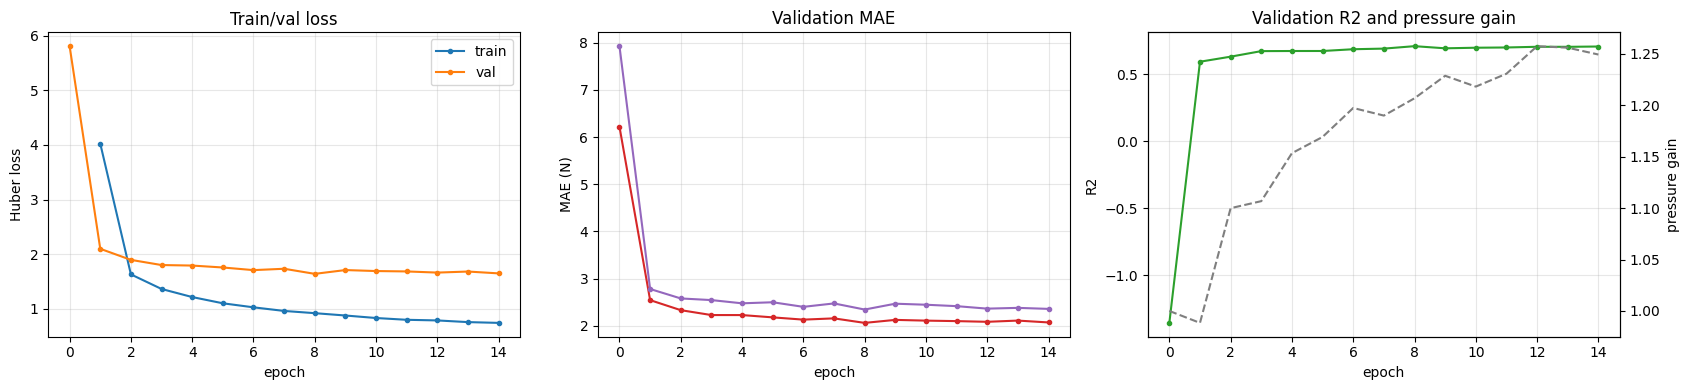

In [12]:
history = pd.read_csv(metrics_path)

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
axes[0].plot(history["epoch"], history["train_loss"], marker=".", label="train")
axes[0].plot(history["epoch"], history["val_loss"], marker=".", label="val")
axes[0].set_xlabel("epoch"); axes[0].set_ylabel("Huber loss"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[0].set_title("Train/val loss")

axes[1].plot(history["epoch"], history["val_mae_n"], marker=".", color="tab:red", label="val MAE (all frames)")
axes[1].plot(history["epoch"], history["val_mae_contact_n"], marker=".", color="tab:purple", label="val MAE (contact frames)")
axes[1].set_xlabel("epoch"); axes[1].set_ylabel("MAE (N)"); axes[1].grid(alpha=0.3)
axes[1].set_title("Validation MAE")

axes[2].plot(history["epoch"], history["val_r2"], marker=".", color="tab:green", label="val R2")
axes[2].set_xlabel("epoch"); axes[2].set_ylabel("R2"); axes[2].grid(alpha=0.3)
gain_axis = axes[2].twinx()
gain_axis.plot(history["epoch"], history["gain"], color="tab:gray", linestyle="--", label="gain")
gain_axis.set_ylabel("pressure gain")
axes[2].set_title("Validation R2 and pressure gain")
fig.tight_layout()

best_epoch = history.loc[history["val_mae_n"].idxmin()]
print(f"Best epoch: {int(best_epoch['epoch'])}  val_mae_n={best_epoch['val_mae_n']:.3f}  "
      f"val_mae_contact_n={best_epoch['val_mae_contact_n']:.3f}  val_r2={best_epoch['val_r2']:.3f}")

## Load the best checkpoint

In [13]:
net, checkpoint = model_module.load_checkpoint(checkpoint_path, device)
run_config = checkpoint["config"]               # the config the checkpoint was trained with
model_config = run_config["model_training"]
splits = checkpoint["splits"]
contact_threshold_n = model_config["training"]["contact_threshold_n"]

print(f"Loaded checkpoint from epoch {checkpoint['epoch']}, init_weights={model_config['model']['init_weights']}, "
      f"gain={checkpoint['gain']:.3f}")
print("Validation metrics at that epoch:")
for key, value in checkpoint["val_metrics"].items():
    print(f"  {key}: {value}")
print("Conventions:")
for key, value in checkpoint["conventions"].items():
    print(f"  {key}: {value}")
for split, names in splits.items():
    print(f"{split} ({len(names)}): {names}")

Loss function: CrossEntropyLoss()
Loaded checkpoint from epoch 8, init_weights=pressurevision, gain=1.207
Validation metrics at that epoch:
  mae_n: 2.062274932861328
  rmse_n: 2.8408448696136475
  r2: 0.7078924179077148
  mae_contact_n: 2.3450636863708496
  contact_acc: 0.8446638340414896
  num_frames: 8002
Conventions:
  input: RGB fingertip crop from preprocessing/dataProcessor.py, /255, PressureVision resnet_preprocessor
  crop_side_mm: 160.0
  crop_output_px: 256
  force_label: max(-Fz_filtered, 0) in N
  force_from_model: sum(pressure_kpa) * 1000 * pixel_area_m2, pixel_area_m2 = (side_mm/output_px/1000)^2
train (25): ['session_20261002_112827', 'session_20261002_113324', 'session_20261002_113816', 'session_20261002_114717', 'session_20261002_115341', 'session_20261002_120655', 'session_20261002_141310', 'session_20261002_141658', 'session_20261002_142033', 'session_20261002_142336', 'session_20261002_143710', 'session_20261002_144236', 'session_20261002_144523', 'session_20261002

## Sample inputs (sanity check)

De-normalized network inputs from the training split with the training augmentation on (flip / rotation / scale / translation / brightness-contrast), with their label and the pixel size the force integral uses. Skin should look natural (RGB order) and the fingertip should be near the centre. `preprocessing/dataViewer.py` shows the same thing interactively, next to the raw frame.

[dataset] Loading train split: 25 session(s), stride 3
  [dataset] session_20261002_112827: 1883 frames, 80% in contact, max 18.3 N
  [dataset] session_20261002_113324: 1727 frames, 84% in contact, max 24.4 N
  [dataset] session_20261002_113816: 2322 frames, 75% in contact, max 14.3 N
  [dataset] session_20261002_114717: 2023 frames, 83% in contact, max 14.7 N
  [dataset] session_20261002_115341: 2508 frames, 79% in contact, max 13.8 N
  [dataset] session_20261002_120655: 2181 frames, 78% in contact, max 23.6 N
  [dataset] session_20261002_141310: 1301 frames, 95% in contact, max 18.2 N
  [dataset] session_20261002_141658: 1557 frames, 83% in contact, max 18.5 N
  [dataset] session_20261002_142033: 1176 frames, 91% in contact, max 21.6 N
  [dataset] session_20261002_142336: 1083 frames, 90% in contact, max 10.5 N
  [dataset] session_20261002_143710: 858 frames, 83% in contact, max 16.6 N
  [dataset] session_20261002_144236: 961 frames, 82% in contact, max 14.4 N
  [dataset] session_202

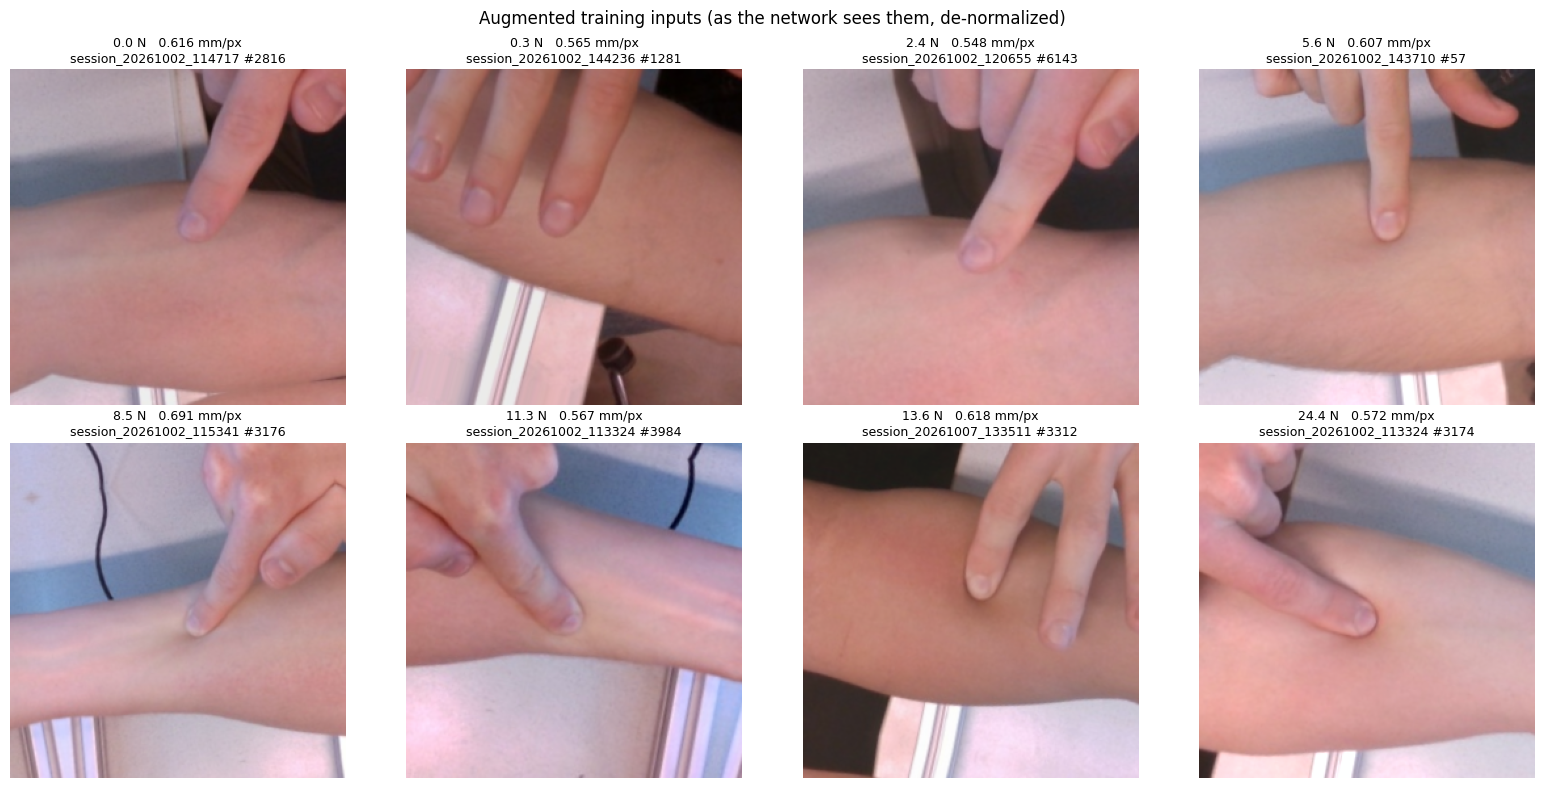

In [14]:
train_dataset = dataset.ForceFrameDataset(model_config, "train", sessions=splits["train"], augment=True)
rgb_mean, rgb_std = np.array([0.485, 0.456, 0.406]), np.array([0.229, 0.224, 0.225])   # recording.util.resnet_preprocessor

order = np.argsort(train_dataset.labels_n())
sample_indices = order[np.linspace(0, len(order) - 1, 8).astype(int)]   # spread over the force range
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for ax, sample_index in zip(axes.ravel(), sample_indices):
    item = train_dataset[int(sample_index)]
    image = np.clip(item["img"].numpy().transpose(1, 2, 0) * rgb_std + rgb_mean, 0, 1)
    pixel_mm = float(np.sqrt(item["pixel_area_m2"].item())) * 1000
    ax.imshow(image)
    ax.set_title(f"{item['force_n'].item():.1f} N   {pixel_mm:.3f} mm/px\n{item['session']} #{item['raw_frame_index']}", fontsize=9)
    ax.axis("off")
fig.suptitle("Augmented training inputs (as the network sees them, de-normalized)")
fig.tight_layout()

## Test-set evaluation

MAE, RMSE, R^2 in newtons on the held-out test sessions, evaluated densely: every usable frame (`TEST_STRIDE = 1`; artifact frames and labels above `max_force_n` are excluded, as in training). `hard` is PressureVision's own argmax-class readout of the same output, for reference. The trivial baseline always predicts the mean train force. The scatter, time-series and per-bin cells below use the same frames.

In [15]:
TEST_STRIDE = 1

test_dataset, test_loader = dataset.build_dataloader("test", run_config, shuffle=False, stride=TEST_STRIDE,
                                                     sessions=splits["test"], augment=False)
loss_fn = torch.nn.HuberLoss(delta=model_config["training"]["loss"]["huber_delta_n"])
test_result = train_module.predict(net, test_loader, device, autocast_dtype, loss_fn)
preds_n, trues_n = test_result["pred_n"], test_result["true_n"]

mean_train_n = float(np.mean(np.concatenate([
    dataset.load_session_frames(os.path.join(dataset.repo_path(model_config["data_root"]), name),
                                model_config["frames"], 1)["force_n"].to_numpy() for name in splits["train"]])))
summary = pd.DataFrame({
    "model (soft)": train_module.regression_metrics(preds_n, trues_n, contact_threshold_n),
    "model (hard argmax)": train_module.regression_metrics(test_result["hard_pred_n"], trues_n, contact_threshold_n),
    "trivial baseline": train_module.regression_metrics(np.full_like(trues_n, mean_train_n), trues_n, contact_threshold_n),
})
print(f"Test set: {len(trues_n)} frames from {len(splits['test'])} session(s), loss={test_result['loss']:.4f}")
display(summary.round(3))

per_session = pd.DataFrame({
    name: train_module.regression_metrics(preds_n[test_result["session"] == name], trues_n[test_result["session"] == name],
                                          contact_threshold_n)
    for name in splits["test"]}).T
display(per_session.round(3))

[dataset] Loading test split: 6 session(s), stride 1
  [dataset] session_20261002_143220: 2396 frames, 79% in contact, max 16.4 N
  [dataset] session_20261002_143513: 2097 frames, 89% in contact, max 16.4 N
  [dataset] session_20261007_113442: 2634 frames, 93% in contact, max 16.9 N
  [dataset] session_20261007_131032: 4845 frames, 90% in contact, max 23.4 N
  [dataset] session_20261007_132021: 2349 frames, 77% in contact, max 10.8 N
  [dataset] session_20261007_132605: 3668 frames, 80% in contact, max 17.0 N
  [dataset] test: 17989 frames total
Test set: 17989 frames from 6 session(s), loss=1.7093


,model (soft),model (hard argmax),trivial baseline
mae_n,2.139,4.387,4.457
rmse_n,3.006,5.553,5.182
r2,0.663,-0.149,-0.000
mae_contact_n,2.374,5.106,3.983
contact_acc,0.860,0.805,0.851
num_frames,17989.000,17989.000,17989.000


,mae_n,rmse_n,r2,mae_contact_n,contact_acc,num_frames
session_20261002_143220,2.137,2.987,0.575,2.296,0.823,2396.0
session_20261002_143513,1.964,2.657,0.716,2.145,0.924,2097.0
session_20261007_113442,2.452,3.194,0.574,2.578,0.909,2634.0
session_20261007_131032,3.075,4.029,0.409,3.313,0.882,4845.0
session_20261007_132021,1.485,1.960,0.734,1.695,0.792,2349.0
session_20261007_132605,1.197,1.795,0.885,1.424,0.826,3668.0


## Predicted vs. true force (scatter)

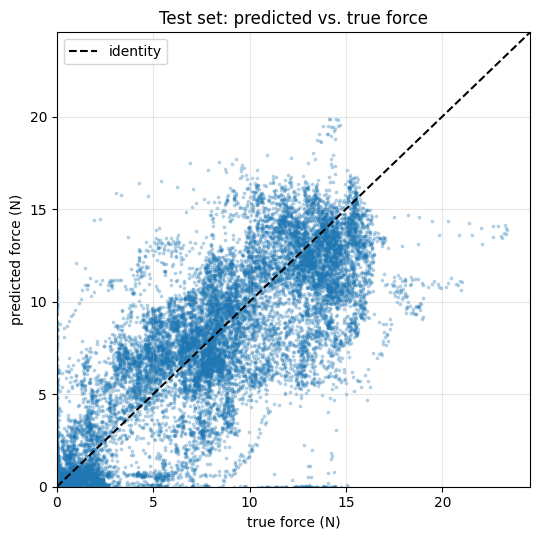

In [16]:
fig, ax = plt.subplots(figsize=(5.5, 5.5))
ax.scatter(trues_n, preds_n, s=3, alpha=0.25)
lims = [0, max(trues_n.max(), preds_n.max()) * 1.05]
ax.plot(lims, lims, "k--", label="identity")
ax.set_xlim(lims); ax.set_ylim(lims)
ax.set_xlabel("true force (N)"); ax.set_ylabel("predicted force (N)"); ax.legend(); ax.grid(alpha=0.3)
ax.set_title("Test set: predicted vs. true force")
fig.tight_layout()

## Predicted vs. true force over time (every test session)

One panel per test session, evaluated at every usable frame - a dense predicted-force curve over each whole trial, where lag, offsets and noise become obvious. Lines are broken where frames are missing (hand not tracked, artifacts) for longer than `MAX_GAP_S`.

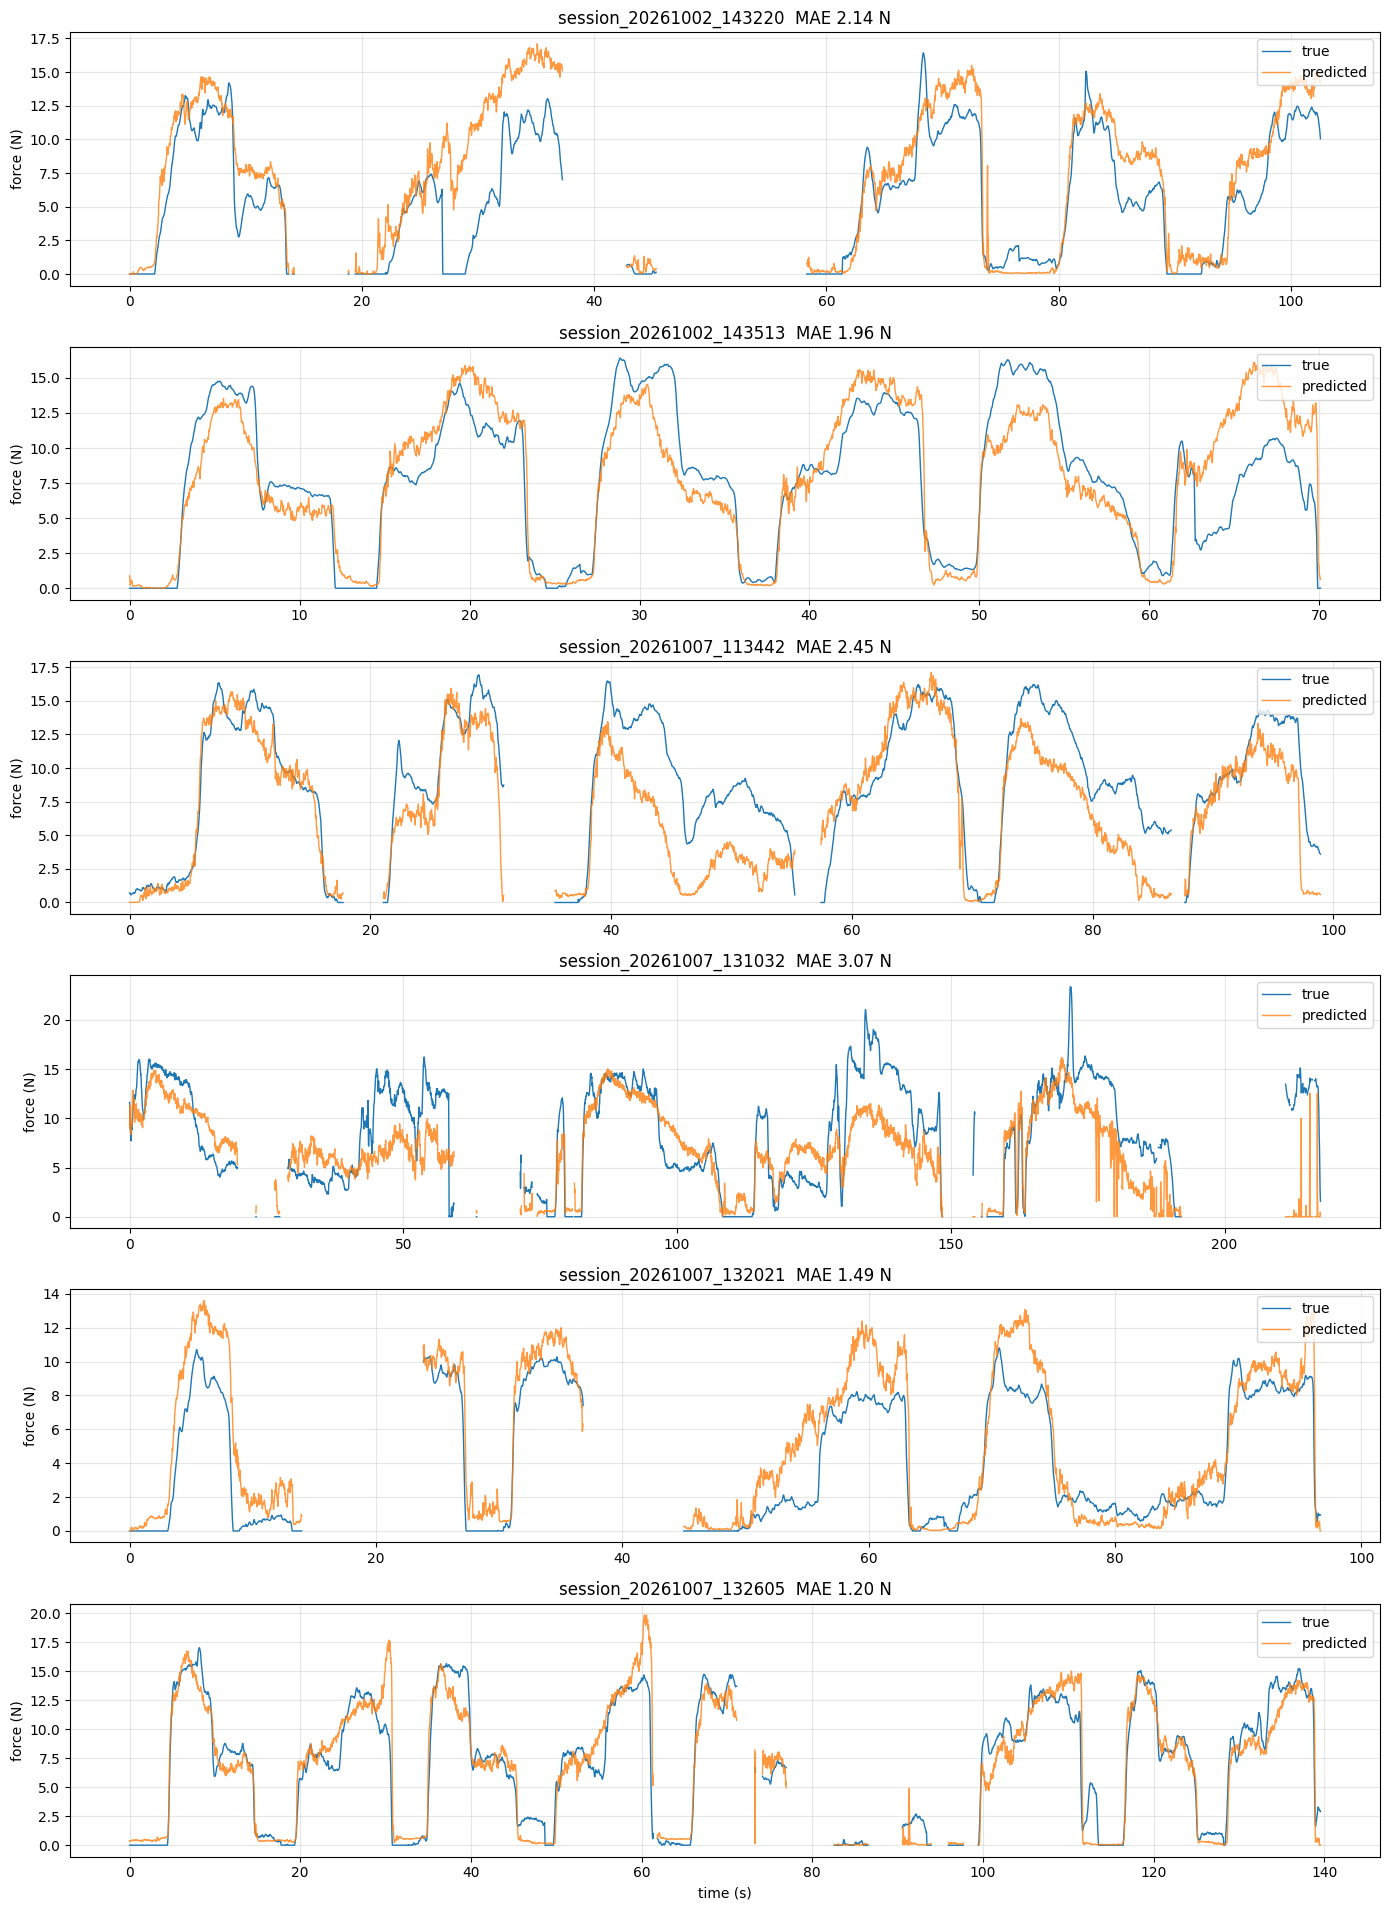

In [17]:
MAX_GAP_S = 0.2

def break_at_gaps(t_s, values, max_gap_s=MAX_GAP_S):
    """Inserts NaN between samples more than max_gap_s apart so matplotlib doesn't draw lines across gaps."""
    gap_idx = np.where(np.diff(t_s) > max_gap_s)[0] + 1
    return np.insert(t_s, gap_idx, np.nan), np.insert(values.astype(float), gap_idx, np.nan)

test_sessions = splits["test"]
fig, axes = plt.subplots(len(test_sessions), 1, figsize=(14, 3.2 * len(test_sessions)), squeeze=False)
for ax, name in zip(axes[:, 0], test_sessions):
    mask = test_result["session"] == name
    ts = test_result["host_ts_ns"][mask]
    order_t = np.argsort(ts)
    t_s = (ts[order_t] - ts.min()) / 1e9
    ax.plot(*break_at_gaps(t_s, trues_n[mask][order_t]), label="true", linewidth=1)
    ax.plot(*break_at_gaps(t_s, preds_n[mask][order_t]), label="predicted", linewidth=1, alpha=0.8)
    mae = np.mean(np.abs(preds_n[mask] - trues_n[mask]))
    ax.set_ylabel("force (N)"); ax.grid(alpha=0.3); ax.legend(loc="upper right")
    ax.set_title(f"{name}  MAE {mae:.2f} N")
axes[-1, 0].set_xlabel("time (s)")
fig.tight_layout()

## Error by force bin

MAE and bias (mean signed error) within each 2 N true-force bin - shows whether the model regresses toward the mean, i.e. underestimates high forces and overestimates near-zero ones.

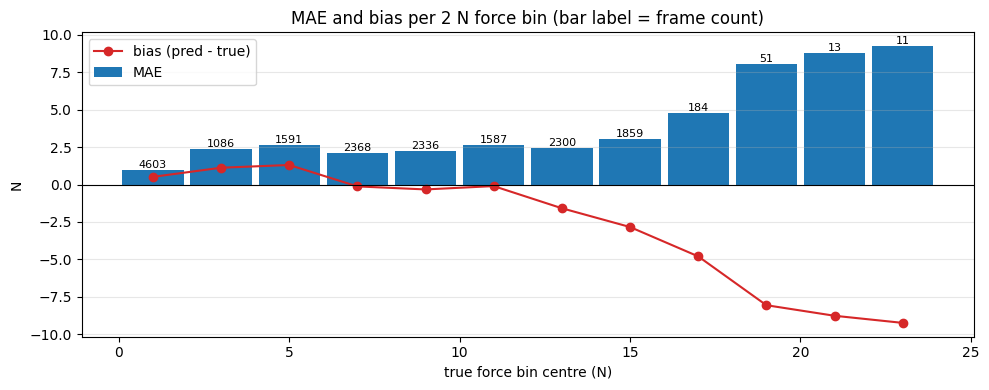

In [18]:
bin_width_n = 2.0
bin_edges = np.arange(0.0, np.ceil(trues_n.max() / bin_width_n) * bin_width_n + bin_width_n, bin_width_n)
bin_index = np.clip(np.digitize(trues_n, bin_edges) - 1, 0, len(bin_edges) - 2)
occupied = np.unique(bin_index)
centers = bin_edges[occupied] + bin_width_n / 2
errors = preds_n - trues_n
bin_maes = [np.abs(errors[bin_index == b]).mean() for b in occupied]
bin_bias = [errors[bin_index == b].mean() for b in occupied]
bin_counts = [(bin_index == b).sum() for b in occupied]

fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.bar(centers, bin_maes, width=bin_width_n * 0.9, color="tab:blue", label="MAE")
ax.plot(centers, bin_bias, "o-", color="tab:red", label="bias (pred - true)")
ax.axhline(0, color="black", linewidth=0.8)
for bar, count in zip(bars, bin_counts):
    ax.text(bar.get_x() + bar.get_width() / 2, bar.get_height(), str(count), ha="center", va="bottom", fontsize=8)
ax.set_xlabel("true force bin centre (N)"); ax.set_ylabel("N"); ax.legend()
ax.set_title("MAE and bias per 2 N force bin (bar label = frame count)")
ax.grid(alpha=0.3, axis="y")
fig.tight_layout()

## Single session, start to finish

Runs one session (from any split) through the model at every usable frame. Change `SESSION_SPLIT` / `SESSION_INDEX` to pick the session, e.g. `"test", 1` = the second test session of the checkpoint's split. Built without augmentation, even for a training session.

[dataset] Loading test split: 1 session(s), stride 1
  [dataset] session_20261002_143513: 2097 frames, 89% in contact, max 16.4 N
  [dataset] test: 2097 frames total
session_20261002_143513: 2097 frames  MAE=1.964 N  RMSE=2.657 N


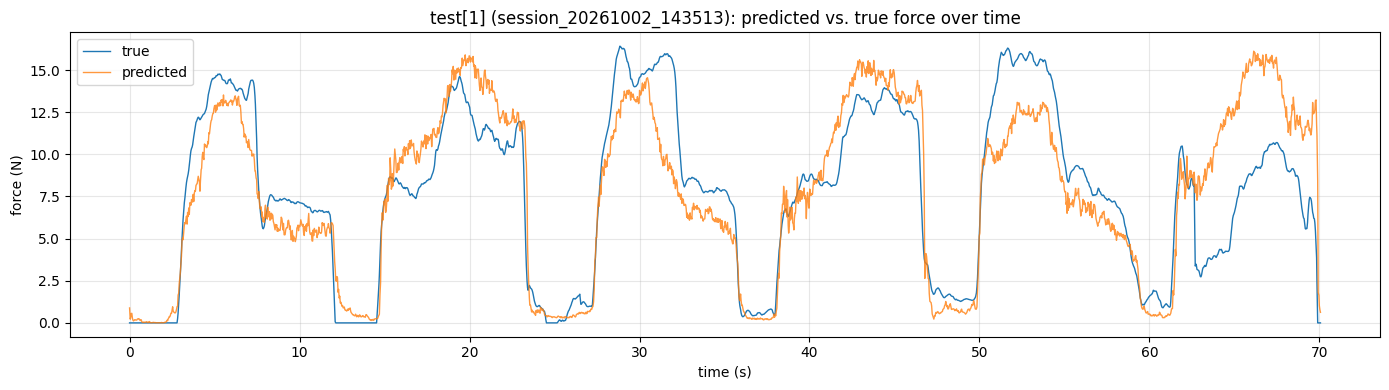

In [19]:
SESSION_SPLIT = "test"          # "train", "val" or "test"
SESSION_INDEX = 1               # index into the checkpoint's splits[SESSION_SPLIT]

session_name = splits[SESSION_SPLIT][SESSION_INDEX]
single_dataset, single_loader = dataset.build_dataloader(SESSION_SPLIT, run_config, shuffle=False, stride=1,
                                                         sessions=[session_name], augment=False)
order_f = np.argsort(single_dataset.labels_n())
example_indices = set(order_f[np.linspace(0, len(order_f) - 1, 8).astype(int)].tolist())
single_result = train_module.predict(net, single_loader, device, autocast_dtype, keep_pressure_for=example_indices)
session_preds_n, session_trues_n = single_result["pred_n"], single_result["true_n"]
session_t_s = (single_result["host_ts_ns"] - single_result["host_ts_ns"].min()) / 1e9

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(*break_at_gaps(session_t_s, session_trues_n), label="true", linewidth=1)
ax.plot(*break_at_gaps(session_t_s, session_preds_n), label="predicted", linewidth=1, alpha=0.8)
ax.set_xlabel("time (s)"); ax.set_ylabel("force (N)"); ax.legend(); ax.grid(alpha=0.3)
ax.set_title(f"{SESSION_SPLIT}[{SESSION_INDEX}] ({session_name}): predicted vs. true force over time")
fig.tight_layout()

session_err = session_preds_n - session_trues_n
print(f"{session_name}: {len(session_preds_n)} frames  MAE={np.abs(session_err).mean():.3f} N  "
      f"RMSE={np.sqrt((session_err ** 2).mean()):.3f} N")

## Single session: predicted pressure maps

The spatial output behind the force: the predicted pressure map (kPa, after the gain) over the crop, for frames spread across the session's force range. Only the map's integral is supervised, so this shows *where* the model has learned to put the pressure - ideally under the fingertip at the crop centre. Uses the session from the cell above.

Text(0.5, 0.98, 'session_20261002_143513: input crops (top) and predicted pressure maps (bottom)')

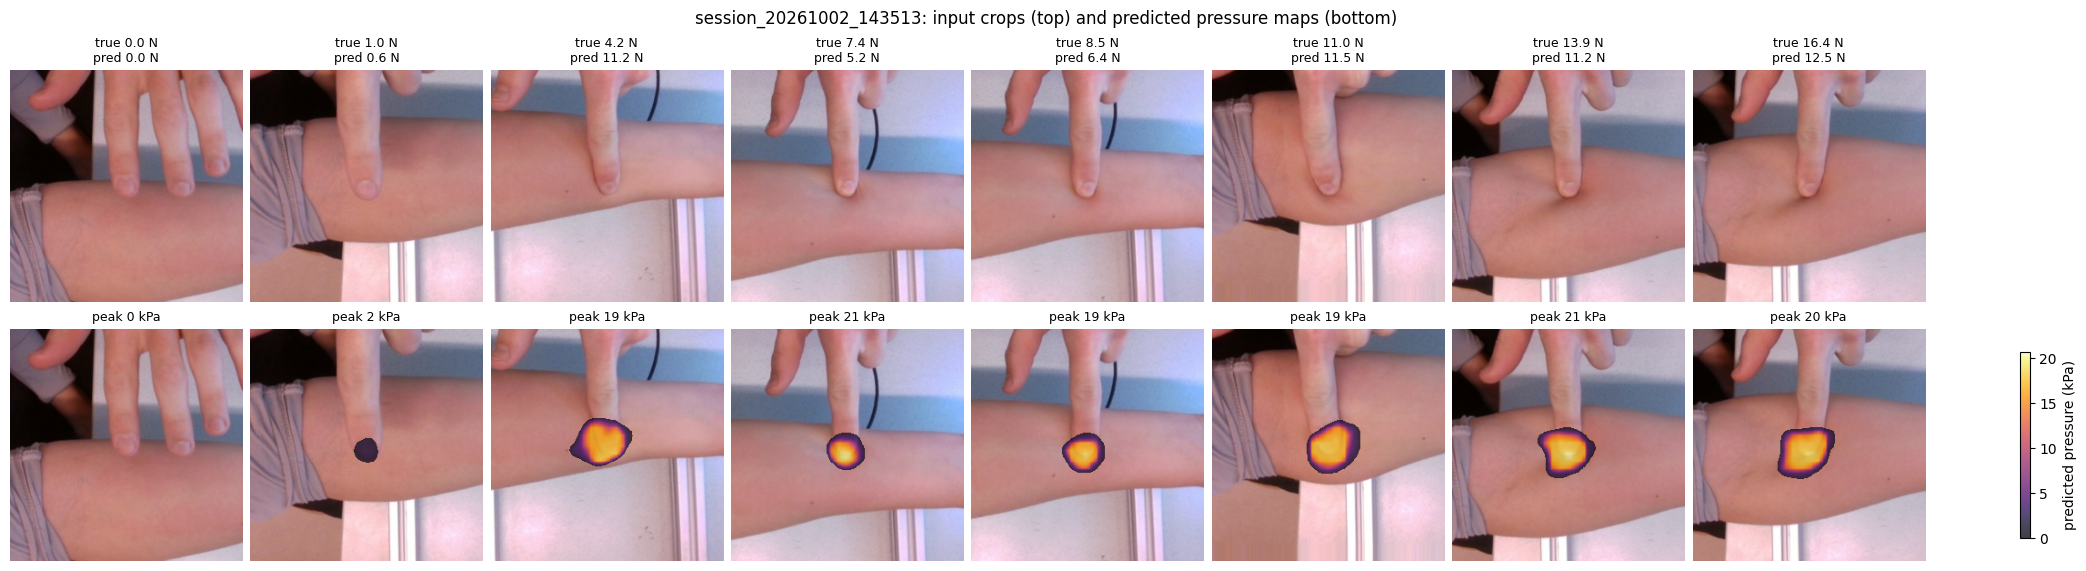

In [20]:
maps = single_result["pressure_maps"]
max_kpa = max(float(p.max()) for _, p in maps.values()) or 1.0
fig, axes = plt.subplots(2, len(maps), figsize=(2.6 * len(maps), 5.6), constrained_layout=True)
for col, index in enumerate(sorted(maps, key=lambda k: session_trues_n[k])):
    image, pressure = maps[index]
    axes[0, col].imshow(np.clip(image.transpose(1, 2, 0), 0, 1))
    axes[0, col].set_title(f"true {session_trues_n[index]:.1f} N\npred {session_preds_n[index]:.1f} N", fontsize=9)
    axes[1, col].imshow(np.clip(image.transpose(1, 2, 0), 0, 1))
    shown = axes[1, col].imshow(np.ma.masked_less(pressure, 0.05 * max_kpa), cmap="inferno", vmin=0, vmax=max_kpa, alpha=0.75)
    axes[1, col].set_title(f"peak {pressure.max():.0f} kPa", fontsize=9)
    for ax in axes[:, col]:
        ax.axis("off")
fig.colorbar(shown, ax=axes[1, :].tolist(), shrink=0.8, label="predicted pressure (kPa)")
fig.suptitle(f"{session_name}: input crops (top) and predicted pressure maps (bottom)")

## Single session: fine-tuned vs. zero-shot PressureVisionNet

Runs the same session through the fine-tuned checkpoint and through the official PressureVisionNet weights without any fine-tuning (gain 1) - what the fine-tuning on forearm data bought. Same statistics as the old pipeline's depth ablation: overall table, contact vs. no-contact MAE, error over time, and per-force-bin MAE. Uses `SESSION_SPLIT` / `SESSION_INDEX` and `single_loader` from the cells above.

Loss function: CrossEntropyLoss()
[model] Loaded official PressureVisionNet weights from /home/wouterdg/ForceEstimationPressureVision/PressureVision/data/model/paper_59.pt
session_20261002_143513: 2097 frames


,fine-tuned,zero-shot PressureVisionNet,difference (fine-tuned - zero-shot)
MAE (N),1.964,7.720,-5.756
RMSE (N),2.657,9.097,-6.439
R2,0.716,-2.326,3.042
Pearson r,0.860,-0.161,1.021
bias (N),0.076,-7.351,7.427
median |err| (N),1.442,8.073,-6.631
P95 |err| (N),6.086,15.189,-9.103
max |err| (N),8.785,16.549,-7.764


no-contact frames: 225   contact frames: 1872


,fine-tuned,zero-shot PressureVisionNet,difference (fine-tuned - zero-shot)
MAE true<=0.5N (N),0.454,1.513,-1.060
MAE true>0.5N (N),2.145,8.466,-6.321


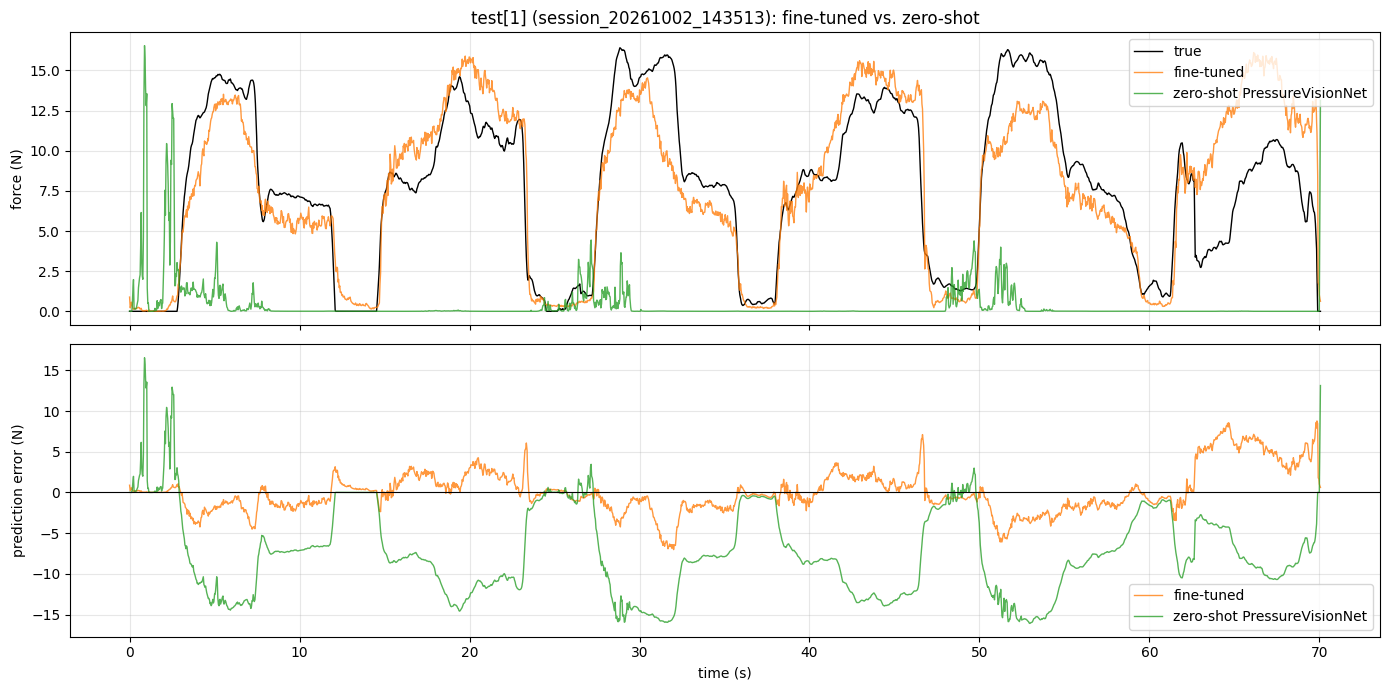

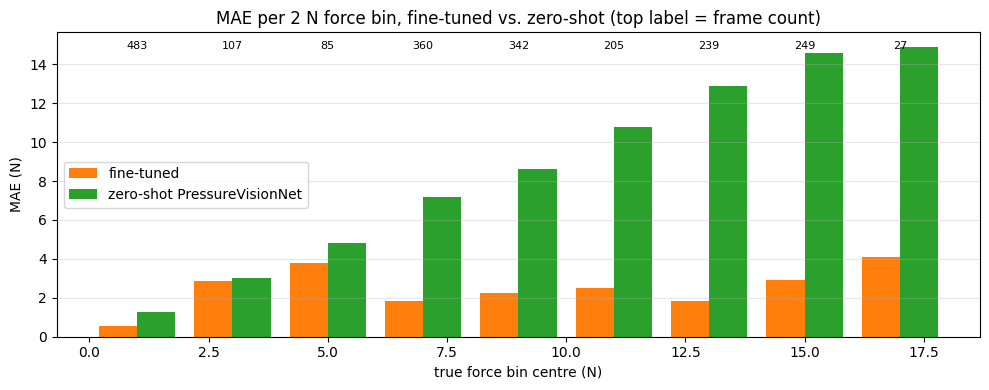

In [21]:
def stats(preds, trues):
    err = preds - trues
    ss_tot = ((trues - trues.mean()) ** 2).sum()
    return {
        "MAE (N)": np.abs(err).mean(),
        "RMSE (N)": np.sqrt((err ** 2).mean()),
        "R2": 1.0 - (err ** 2).sum() / ss_tot if ss_tot > 0 else np.nan,
        "Pearson r": np.corrcoef(preds, trues)[0, 1] if preds.std() > 0 else np.nan,
        "bias (N)": err.mean(),
        "median |err| (N)": np.median(np.abs(err)),
        "P95 |err| (N)": np.percentile(np.abs(err), 95),
        "max |err| (N)": np.abs(err).max(),
    }

zero_shot_net = model_module.build_model(model_config, device, init_weights="pressurevision").eval()
zero_shot_result = train_module.predict(zero_shot_net, single_loader, device, autocast_dtype)
del zero_shot_net
comparison_preds = {"fine-tuned": session_preds_n, "zero-shot PressureVisionNet": zero_shot_result["pred_n"]}

stats_table = pd.DataFrame({name: stats(preds, session_trues_n) for name, preds in comparison_preds.items()})
stats_table["difference (fine-tuned - zero-shot)"] = stats_table["fine-tuned"] - stats_table["zero-shot PressureVisionNet"]
print(f"{session_name}: {len(session_trues_n)} frames")
display(stats_table.round(3))

contact_mask = session_trues_n > contact_threshold_n
split_table = pd.DataFrame({
    name: {f"MAE true<={contact_threshold_n}N (N)": np.abs(preds - session_trues_n)[~contact_mask].mean() if (~contact_mask).any() else np.nan,
           f"MAE true>{contact_threshold_n}N (N)": np.abs(preds - session_trues_n)[contact_mask].mean() if contact_mask.any() else np.nan}
    for name, preds in comparison_preds.items()})
split_table["difference (fine-tuned - zero-shot)"] = split_table["fine-tuned"] - split_table["zero-shot PressureVisionNet"]
print(f"no-contact frames: {(~contact_mask).sum()}   contact frames: {contact_mask.sum()}")
display(split_table.round(3))

colors = ["tab:orange", "tab:green"]
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
axes[0].plot(*break_at_gaps(session_t_s, session_trues_n), label="true", linewidth=1, color="black")
for (name, preds), color in zip(comparison_preds.items(), colors):
    axes[0].plot(*break_at_gaps(session_t_s, preds), label=name, linewidth=1, alpha=0.8, color=color)
    axes[1].plot(*break_at_gaps(session_t_s, preds - session_trues_n), label=name, linewidth=1, alpha=0.8, color=color)
axes[0].set_ylabel("force (N)"); axes[0].legend(); axes[0].grid(alpha=0.3)
axes[0].set_title(f"{SESSION_SPLIT}[{SESSION_INDEX}] ({session_name}): fine-tuned vs. zero-shot")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_xlabel("time (s)"); axes[1].set_ylabel("prediction error (N)"); axes[1].legend(); axes[1].grid(alpha=0.3)
fig.tight_layout()

bin_edges_c = np.arange(0.0, np.ceil(session_trues_n.max() / bin_width_n) * bin_width_n + bin_width_n, bin_width_n)
bin_index_c = np.clip(np.digitize(session_trues_n, bin_edges_c) - 1, 0, len(bin_edges_c) - 2)
occupied_c = np.unique(bin_index_c)
centers_c = bin_edges_c[occupied_c] + bin_width_n / 2
fig, ax = plt.subplots(figsize=(10, 4))
bar_width = bin_width_n * 0.4
for offset, ((name, preds), color) in zip([-bar_width / 2, bar_width / 2], zip(comparison_preds.items(), colors)):
    ax.bar(centers_c + offset, [np.abs(preds - session_trues_n)[bin_index_c == b].mean() for b in occupied_c],
           width=bar_width, label=name, color=color)
for center, count in zip(centers_c, [(bin_index_c == b).sum() for b in occupied_c]):
    ax.text(center, ax.get_ylim()[1] * 0.97, str(count), ha="center", va="top", fontsize=8)
ax.set_xlabel("true force bin centre (N)"); ax.set_ylabel("MAE (N)"); ax.legend(); ax.grid(alpha=0.3, axis="y")
ax.set_title("MAE per 2 N force bin, fine-tuned vs. zero-shot (top label = frame count)")
fig.tight_layout()